# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 8: Comparativo Multimodal Global — MEL, DEMON, LOFAR e FUSÃO (MEL + DEMON)
#### Modelos Avaliados: Multi-Layer Perceptron (MLP), SVM Nyström, Random Forest e CNN 2D

Este notebook avalia a interação entre **quatro representações acústicas** e **quatro famílias de aprendizado de máquina** sob o protocolo oficial de **$5\times2$ validação cruzada (10 folds)** com **particionamento por gravação de áudio (`ID`, `exclusive_header='ID'` em `src/iara/ml/experiment.py`)** sobre os **1.706 áudios de UO** (*Silva et al.*, IEEE Access 2025, Seção V-D: *"samples from the same audio recording were not placed in different sets"*). O particionamento não isola navios: gravações diferentes do mesmo navio podem cair em treino e teste.

> **Nota metodológica:**
> * **ACC = acurácia balanceada** (média dos recalls; a coluna `ACC` da Tabela 7 do artigo) em todas as tabelas. Acurácia micro não é usada.
> * Todos os números locais são recalculados das predições por janela em `results/trainings/` por `notebooks/iara_results.py`. Os valores do artigo vêm de `R.ARTICLE_TABLE7` (Tabela 7, só 4 classes) e aparecem em tabela **separada**.
> * **Duas grades temporais:** os experimentos do pipeline iara oficial (`results/trainings/tests`: MLP/CNN/SVM com MEL ou LOFAR) usam janelas de **0,512 s**; o DEMON, a FUSÃO e os caches `mel5s`/`lofar5s` usam **um vetor a cada 5,12 s** (MEL/LOFAR com média de 10 frames, resolução temporal 10× menor). A coluna `Grade` indica qual é qual.
> * **"3 classes"** aparece em dois modos, sempre rotulados: `4c_sem_bg` (modelo 4c avaliado só em navios; prever BG = erro) e `3c` (modelo **retreinado** sem BG, só onde existe).

---

### Representações Espectrais Avaliadas:
1. **MEL (256 filtros log-triangulares):** energia de banda larga de **$0\text{ a }8\text{ kHz}$** (Nyquist do sinal decimado a $16\text{ kHz}$).
2. **DEMON (253 bins de modulação):** envoltória da banda de 1–2 kHz demodulada em **$0{,}39\text{ a }25\text{ Hz}$** (Nyquist da envoltória decimada a $50\text{ Hz}$). A FFT de $N_{\text{FFT}}=512$ tem 257 bins; os **4** primeiros ($0$; $0{,}098$; $0{,}195$; $0{,}293\text{ Hz}$) são descartados (`discard_dc_bins = 4` em `scratch/extract_all_demon.py`).
3. **LOFAR (1024 bins de banda estreita linear):** espectrograma de **$0\text{ a }8\text{ kHz}$** ($N_{\text{FFT}}=2048$ sobre o sinal a $16\text{ kHz}$).
4. **FUSÃO MULTIMODAL (509 atributos):** concatenação $\text{MEL}_{5{,}12\text{ s}} (256) + \text{DEMON} (253)$ na grade de $5{,}12\text{ s}$.

---

### Famílias de Aprendizado de Máquina:
1. **MLP (PyTorch):** camadas densas com `BatchNorm1d` e `Dropout`. **Atenção:** a MLP da FUSÃO usa `[64, 32]`; as MLP de MEL 5,12 s e DEMON usam `[32, 16]`.
2. **SVM Nyström:** kernel RBF aproximado com penalização ElasticNet; $m=6000$ para DEMON, LOFAR e FUSÃO e **$m=4000$ para MEL** (o único SVM MEL oficial em disco).
3. **Random Forest (100 árvores):** `class_weight='balanced'`.
4. **CNN 2D:** CNN oficial do artigo para MEL; CNNs **ad hoc** (PyTorch) para DEMON, LOFAR 5,12 s e FUSÃO — estas três colapsaram e não devem ser usadas como baseline.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10, 'figure.titlesize': 15, 'figure.dpi': 130})

## 1. Tabela Mestra Comparativa Global ($4 \times 4$)

Os 16 pares (Modelo × Representação), com o experimento em disco, a grade temporal e a origem de cada linha. Abaixo dela: a mesma matriz em `4c_sem_bg`, os modelos retreinados sem BG (`3c`), a Tabela 7 do artigo e a rastreabilidade artigo × avaliação local.

* O recall SMALL do `SVM m=6000 | LOFAR` é **38,15%** (uma versão anterior trazia 42,58%, provavelmente um valor 3C).
* A linha SVM | MEL é o modelo **m=4000** (uma versão anterior a rotulava como m=6000).
* **Três MLP DEMON [32,16]** distintos existem no projeto (tabela abaixo): 25 épocas (51,76 ± 2,75%, NB7), 30 épocas com seed 42 (53,06 ± 2,39%, NBs 14–16 e gate) e 35 épocas (53,09 ± 2,69%, usada aqui por estar na mesma grade e no mesmo script da FUSÃO).

In [2]:
MODELS = ['MLP', 'SVM Nyström', 'Random Forest', 'CNN 2D']
REPS = ['DEMON', 'MEL', 'LOFAR', 'FUSÃO (MEL+DEMON)']
# (modelo, representação) -> (rótulo, experimento 4c, experimento 3c retreinado ou None, grade temporal, observação)
GRID = {
    ('MLP', 'DEMON'): ('MLP [32,16] 35 ép. | DEMON', 'mlp_demon_h32-16_e35_4c', 'mlp_demon_h32-16_e35_3c', '5,12 s', 'eval_fusion_mel_demon_5x2cv.py'),
    ('MLP', 'MEL'): ('MLP [32,16] 35 ép. | MEL 5,12 s', 'mlp_mel5s_h32-16_e35_4c', 'mlp_mel5s_h32-16_e35_3c', '5,12 s', 'eval_fusion_mel_demon_5x2cv.py'),
    ('MLP', 'LOFAR'): ('MLP oficial | LOFAR', 'mlp_lofar', None, '0,512 s', 'pipeline iara (early stopping)'),
    ('MLP', 'FUSÃO (MEL+DEMON)'): ('MLP [64,32] 35 ép. | FUSÃO', 'mlp_mel5s-demon_h64-32_e35_4c', 'mlp_mel5s-demon_h64-32_e35_3c', '5,12 s', 'eval_fusion_mel_demon_5x2cv.py (rede MAIOR)'),
    ('SVM Nyström', 'DEMON'): ('SVM m=6000 | DEMON', 'svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.15_it1000_4c', 'svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.15_it1000_3c', '5,12 s', 'eval_demon_svm_5x2cv.py'),
    ('SVM Nyström', 'MEL'): ('SVM m=4000 | MEL', 'svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0', None, '0,512 s', 'pipeline iara (m=4000, não 6000)'),
    ('SVM Nyström', 'LOFAR'): ('SVM m=6000 | LOFAR', 'svm_nystroem_6000_lofar_elasticnet_l1r0.15', None, '0,512 s', 'pipeline iara'),
    ('SVM Nyström', 'FUSÃO (MEL+DEMON)'): ('SVM m=6000 | FUSÃO', 'svm_nystroem_6000_mel5s-demon_C2.0_elasticnet_l1r0.15_4c', 'svm_nystroem_6000_mel5s-demon_C2.0_elasticnet_l1r0.15_3c', '5,12 s', 'eval_fusion_svm_cnn_5x2cv.py'),
    ('Random Forest', 'DEMON'): ('RF 100 árv. | DEMON', 'rf_demon_n100_balanced_4c', 'rf_demon_n100_balanced_3c', '5,12 s', 'eval_demon_baselines_5x2cv.py'),
    ('Random Forest', 'MEL'): ('RF 100 árv. | MEL 5,12 s', 'rf_mel5s_n100_balanced_4c', None, '5,12 s', 'generate_rf_predictions_and_analysis.py'),
    ('Random Forest', 'LOFAR'): ('RF 100 árv. | LOFAR 5,12 s', 'rf_lofar5s_n100_balanced_4c', None, '5,12 s', 'generate_rf_predictions_and_analysis.py'),
    ('Random Forest', 'FUSÃO (MEL+DEMON)'): ('RF 100 árv. | FUSÃO', 'rf_mel5s-demon_n100_balanced_4c', 'rf_mel5s-demon_n100_balanced_3c', '5,12 s', 'eval_rf_fusion_5x2cv.py'),
    ('CNN 2D', 'DEMON'): ('CNN 2D ad hoc | DEMON', 'cnn2d_demon_w32_b32_e20_4c', 'cnn2d_demon_w32_b32_e20_3c', '5,12 s', 'eval_demon_baselines_5x2cv.py [COLAPSADA]'),
    ('CNN 2D', 'MEL'): ('CNN oficial | MEL', 'cnn', None, '0,512 s', 'pipeline iara'),
    ('CNN 2D', 'LOFAR'): ('CNN 2D ad hoc | LOFAR 5,12 s', 'cnn2d_lofar5s_w32_b64_e15_4c', None, '5,12 s', 'generate_cnn_predictions_and_analysis.py [COLAPSADA]'),
    ('CNN 2D', 'FUSÃO (MEL+DEMON)'): ('CNN 2D ad hoc | FUSÃO', 'cnn2d_mel5s-demon_w32_b32_e25_4c', 'cnn2d_mel5s-demon_w32_b32_e25_3c', '5,12 s', 'eval_fusion_svm_cnn_5x2cv.py [COLAPSADA]'),
}
S4 = {k: R.summary(v[1], '4c') for k, v in GRID.items()}
SB = {k: R.summary(v[1], '4c_sem_bg') for k, v in GRID.items()}
S3 = {k: R.summary(v[2], '3c') for k, v in GRID.items() if v[2]}


def row(k, S, extra=None):
    lbl, e4, e3, grade, obs = GRID[k]
    s = S[k]
    d = {'Modelo': k[0], 'Representação': k[1], 'Configuração': lbl, 'Grade': grade,
         'SP': R.fmt(s['SP']), 'ACC (bal.)': R.fmt(s['ACC']), 'F1': R.fmt(s['F1']),
         'Rec SMALL': round(s['R_SMALL'][0], 2), 'Rec MEDIUM': round(s['R_MEDIUM'][0], 2), 'Rec LARGE': round(s['R_LARGE'][0], 2)}
    if 'R_BACKGROUND' in s:
        d['Rec BG'] = round(s['R_BACKGROUND'][0], 2)
    d['Origem'] = obs
    d['Experimento'] = e3 if S is S3 else e4
    return d


KEYS = [(m, r) for m in MODELS for r in REPS]
df_master = pd.DataFrame([row(k, S4) for k in KEYS])
df_sem_bg = pd.DataFrame([row(k, SB) for k in KEYS])
df_3c = pd.DataFrame([row(k, S3) for k in KEYS if k in S3])

tab_artigo = pd.DataFrame([{'Par': f'{m} | {r}', **{k: R.fmt(v) for k, v in R.ARTICLE_TABLE7[(m, r)].items()}}
                           for (m, r) in R.ARTICLE_TABLE7]).set_index('Par')
LOCAL_OF_ARTICLE = {('RF', 'MEL'): ('Random Forest', 'MEL'), ('RF', 'LOFAR'): ('Random Forest', 'LOFAR'),
                    ('MLP', 'MEL'): None, ('MLP', 'LOFAR'): ('MLP', 'LOFAR'),
                    ('CNN', 'MEL'): ('CNN 2D', 'MEL'), ('CNN', 'LOFAR'): ('CNN 2D', 'LOFAR')}
rast = []
for (m, r), v in R.ARTICLE_TABLE7.items():
    if LOCAL_OF_ARTICLE[(m, r)] is None:
        lbl, exp, grade = 'MLP oficial | MEL', 'mlp', '0,512 s'
    else:
        lbl, exp, _, grade, _ = GRID[LOCAL_OF_ARTICLE[(m, r)]]
    s = R.summary(exp)
    rast.append({'Par': f'{m} | {r}', 'Artigo SP': R.fmt(v['SP']), 'Artigo ACC': R.fmt(v['ACC']),
                 'Local': lbl, 'Grade local': grade, 'Local SP': R.fmt(s['SP']), 'Local ACC': R.fmt(s['ACC']),
                 'Local Rec SMALL': round(s['R_SMALL'][0], 2), 'Experimento': exp})
df_rast = pd.DataFrame(rast).set_index('Par')

MLP_DEMON = [('25 ép. (NB7)', 'mlp_demon_h32-16_e25_4c'), ('30 ép., seed 42 (NBs 14–16, gate)', 'mlp_demon_h32-16_e30_4c'),
             ('35 ép. (grade da fusão, este NB)', 'mlp_demon_h32-16_e35_4c')]
tab_mlp_demon = R.table([(f'MLP [32,16] DEMON {l}', e) for l, e in MLP_DEMON], metrics=('SP', 'ACC', 'F1'))
SP_FOLDS = {k: R.fold_metrics(GRID[k][1])['SP'].round(1).tolist() for k in KEYS}

print('4 classes (modelos 4c):'); display(df_master)
print('Só navios, modelos 4c (prever BACKGROUND = erro):'); display(df_sem_bg)
print('Só navios, modelos RETREINADOS sem BACKGROUND (3c):'); display(df_3c)
print('Tabela 7 do artigo (Silva et al., 2025; 4 classes):'); display(tab_artigo)
print('Rastreabilidade: Tabela 7 do artigo vs. avaliação local:'); display(df_rast)
print('Os três MLP DEMON [32,16] do projeto (4c):'); display(tab_mlp_demon)

4 classes (modelos 4c):


,Modelo,Representação,Configuração,Grade,SP,ACC (bal.),F1,Rec SMALL,Rec MEDIUM,Rec LARGE,Rec BG,Origem,Experimento
0,MLP,DEMON,"MLP [32,16] 35 ép. | DEMON","5,12 s",53.09 ± 2.69,55.08 ± 1.75,52.13 ± 2.39,31.85,46.64,64.77,77.04,eval_fusion_mel_demon_5x2cv.py,mlp_demon_h32-16_e35_4c
1,MLP,MEL,"MLP [32,16] 35 ép. | MEL 5,12 s","5,12 s",64.16 ± 2.19,64.96 ± 1.88,64.37 ± 2.38,46.07,67.92,66.87,78.98,eval_fusion_mel_demon_5x2cv.py,mlp_mel5s_h32-16_e35_4c
2,MLP,LOFAR,MLP oficial | LOFAR,"0,512 s",66.24 ± 1.78,67.22 ± 1.65,66.42 ± 1.87,46.35,61.48,74.72,86.33,pipeline iara (early stopping),mlp_lofar
3,MLP,FUSÃO (MEL+DEMON),"MLP [64,32] 35 ép. | FUSÃO","5,12 s",66.92 ± 1.59,67.40 ± 1.58,66.99 ± 1.54,53.03,63.83,70.89,81.84,eval_fusion_mel_demon_5x2cv.py (rede MAIOR),mlp_mel5s-demon_h64-32_e35_4c
4,SVM Nyström,DEMON,SVM m=6000 | DEMON,"5,12 s",44.95 ± 4.58,52.73 ± 1.86,46.99 ± 2.63,11.85,47.72,79.21,72.14,eval_demon_svm_5x2cv.py,svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.1...
5,SVM Nyström,MEL,SVM m=4000 | MEL,"0,512 s",63.78 ± 1.14,64.56 ± 1.18,64.32 ± 1.02,50.73,60.40,69.25,77.86,"pipeline iara (m=4000, não 6000)",svm_nystroem_4000_log_melgram_elasticnet_l1r0....
6,SVM Nyström,LOFAR,SVM m=6000 | LOFAR,"0,512 s",63.83 ± 1.91,65.47 ± 1.77,63.58 ± 1.72,38.15,60.40,76.31,87.04,pipeline iara,svm_nystroem_6000_lofar_elasticnet_l1r0.15
7,SVM Nyström,FUSÃO (MEL+DEMON),SVM m=6000 | FUSÃO,"5,12 s",64.67 ± 1.41,65.60 ± 1.27,64.91 ± 1.51,46.24,63.69,72.90,79.59,eval_fusion_svm_cnn_5x2cv.py,svm_nystroem_6000_mel5s-demon_C2.0_elasticnet_...
8,Random Forest,DEMON,RF 100 árv. | DEMON,"5,12 s",44.44 ± 2.24,46.08 ± 1.79,47.16 ± 1.94,52.47,35.10,68.79,27.96,eval_demon_baselines_5x2cv.py,rf_demon_n100_balanced_4c
9,Random Forest,MEL,"RF 100 árv. | MEL 5,12 s","5,12 s",61.50 ± 1.89,61.61 ± 1.88,63.27 ± 1.68,57.87,58.72,67.10,62.76,generate_rf_predictions_and_analysis.py,rf_mel5s_n100_balanced_4c


Só navios, modelos 4c (prever BACKGROUND = erro):


,Modelo,Representação,Configuração,Grade,SP,ACC (bal.),F1,Rec SMALL,Rec MEDIUM,Rec LARGE,Origem,Experimento
0,MLP,DEMON,"MLP [32,16] 35 ép. | DEMON","5,12 s",46.21 ± 2.94,47.75 ± 1.79,50.88 ± 2.73,31.85,46.64,64.77,eval_fusion_mel_demon_5x2cv.py,mlp_demon_h32-16_e35_4c
1,MLP,MEL,"MLP [32,16] 35 ép. | MEL 5,12 s","5,12 s",59.61 ± 2.89,60.29 ± 2.56,60.54 ± 2.85,46.07,67.92,66.87,eval_fusion_mel_demon_5x2cv.py,mlp_mel5s_h32-16_e35_4c
2,MLP,LOFAR,MLP oficial | LOFAR,"0,512 s",60.17 ± 2.12,60.85 ± 2.05,61.68 ± 1.91,46.35,61.48,74.72,pipeline iara (early stopping),mlp_lofar
3,MLP,FUSÃO (MEL+DEMON),"MLP [64,32] 35 ép. | FUSÃO","5,12 s",62.30 ± 1.47,62.58 ± 1.51,63.65 ± 1.25,53.03,63.83,70.89,eval_fusion_mel_demon_5x2cv.py (rede MAIOR),mlp_mel5s-demon_h64-32_e35_4c
4,SVM Nyström,DEMON,SVM m=6000 | DEMON,"5,12 s",38.26 ± 6.13,46.26 ± 3.24,46.13 ± 3.16,11.85,47.72,79.21,eval_demon_svm_5x2cv.py,svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.1...
5,SVM Nyström,MEL,SVM m=4000 | MEL,"0,512 s",59.46 ± 1.67,60.13 ± 1.29,60.73 ± 1.69,50.73,60.40,69.25,"pipeline iara (m=4000, não 6000)",svm_nystroem_4000_log_melgram_elasticnet_l1r0....
6,SVM Nyström,LOFAR,SVM m=6000 | LOFAR,"0,512 s",56.96 ± 1.98,58.29 ± 1.75,59.18 ± 1.61,38.15,60.40,76.31,pipeline iara,svm_nystroem_6000_lofar_elasticnet_l1r0.15
7,SVM Nyström,FUSÃO (MEL+DEMON),SVM m=6000 | FUSÃO,"5,12 s",60.08 ± 1.68,60.94 ± 1.70,61.60 ± 1.61,46.24,63.69,72.90,eval_fusion_svm_cnn_5x2cv.py,svm_nystroem_6000_mel5s-demon_C2.0_elasticnet_...
8,Random Forest,DEMON,RF 100 árv. | DEMON,"5,12 s",50.95 ± 2.12,52.12 ± 2.00,52.89 ± 2.00,52.47,35.10,68.79,eval_demon_baselines_5x2cv.py,rf_demon_n100_balanced_4c
9,Random Forest,MEL,"RF 100 árv. | MEL 5,12 s","5,12 s",61.12 ± 1.74,61.23 ± 1.76,61.47 ± 1.90,57.87,58.72,67.10,generate_rf_predictions_and_analysis.py,rf_mel5s_n100_balanced_4c


Só navios, modelos RETREINADOS sem BACKGROUND (3c):


...

,SP,ACC,F1
Par,,,
RF | MEL,62.22 ± 1.86,62.64 ± 1.84,63.79 ± 1.73
RF | LOFAR,56.92 ± 1.69,58.87 ± 1.68,58.00 ± 1.41
MLP | MEL,63.38 ± 1.81,64.51 ± 1.75,62.89 ± 1.68
MLP | LOFAR,66.51 ± 1.39,67.48 ± 1.24,66.72 ± 1.17
CNN | MEL,63.52 ± 2.26,64.99 ± 2.09,63.04 ± 2.02
CNN | LOFAR,66.05 ± 1.90,67.02 ± 1.78,66.29 ± 2.13


Rastreabilidade: Tabela 7 do artigo vs. avaliação local:


,Artigo SP,Artigo ACC,Local,Grade local,Local SP,Local ACC,Local Rec SMALL,Experimento
Par,,,,,,,,
RF | MEL,62.22 ± 1.86,62.64 ± 1.84,"RF 100 árv. | MEL 5,12 s","5,12 s",61.50 ± 1.89,61.61 ± 1.88,57.87,rf_mel5s_n100_balanced_4c
RF | LOFAR,56.92 ± 1.69,58.87 ± 1.68,"RF 100 árv. | LOFAR 5,12 s","5,12 s",63.07 ± 1.81,63.79 ± 1.70,47.81,rf_lofar5s_n100_balanced_4c
MLP | MEL,63.38 ± 1.81,64.51 ± 1.75,MLP oficial | MEL,"0,512 s",64.74 ± 2.05,65.73 ± 1.90,44.78,mlp
MLP | LOFAR,66.51 ± 1.39,67.48 ± 1.24,MLP oficial | LOFAR,"0,512 s",66.24 ± 1.78,67.22 ± 1.65,46.35,mlp_lofar
CNN | MEL,63.52 ± 2.26,64.99 ± 2.09,CNN oficial | MEL,"0,512 s",63.80 ± 2.23,65.01 ± 2.05,40.90,cnn
CNN | LOFAR,66.05 ± 1.90,67.02 ± 1.78,"CNN 2D ad hoc | LOFAR 5,12 s","5,12 s",35.40 ± 12.38,47.58 ± 2.43,39.21,cnn2d_lofar5s_w32_b64_e15_4c


Os três MLP DEMON [32,16] do projeto (4c):


,SP,ACC,F1,SMALL,MEDIUM,LARGE,BACKGROUND,Experimento
Modelo,,,,,,,,
"MLP [32,16] DEMON 25 ép. (NB7)",51.76 ± 2.75,54.04 ± 2.54,50.39 ± 3.25,30.00,48.32,59.07,78.78,mlp_demon_h32-16_e25_4c
"MLP [32,16] DEMON 30 ép., seed 42 (NBs 14–16, gate)",53.06 ± 2.39,55.14 ± 1.68,52.20 ± 2.28,32.19,43.29,67.34,77.76,mlp_demon_h32-16_e30_4c
"MLP [32,16] DEMON 35 ép. (grade da fusão, este NB)",53.09 ± 2.69,55.08 ± 1.75,52.13 ± 2.39,31.85,46.64,64.77,77.04,mlp_demon_h32-16_e35_4c


## 2. Gráfico 1: Índice SP por Modelo e Representação

Os modelos marcados com `*` são as CNNs ad hoc colapsadas (SP baixo e desvio alto entre folds):

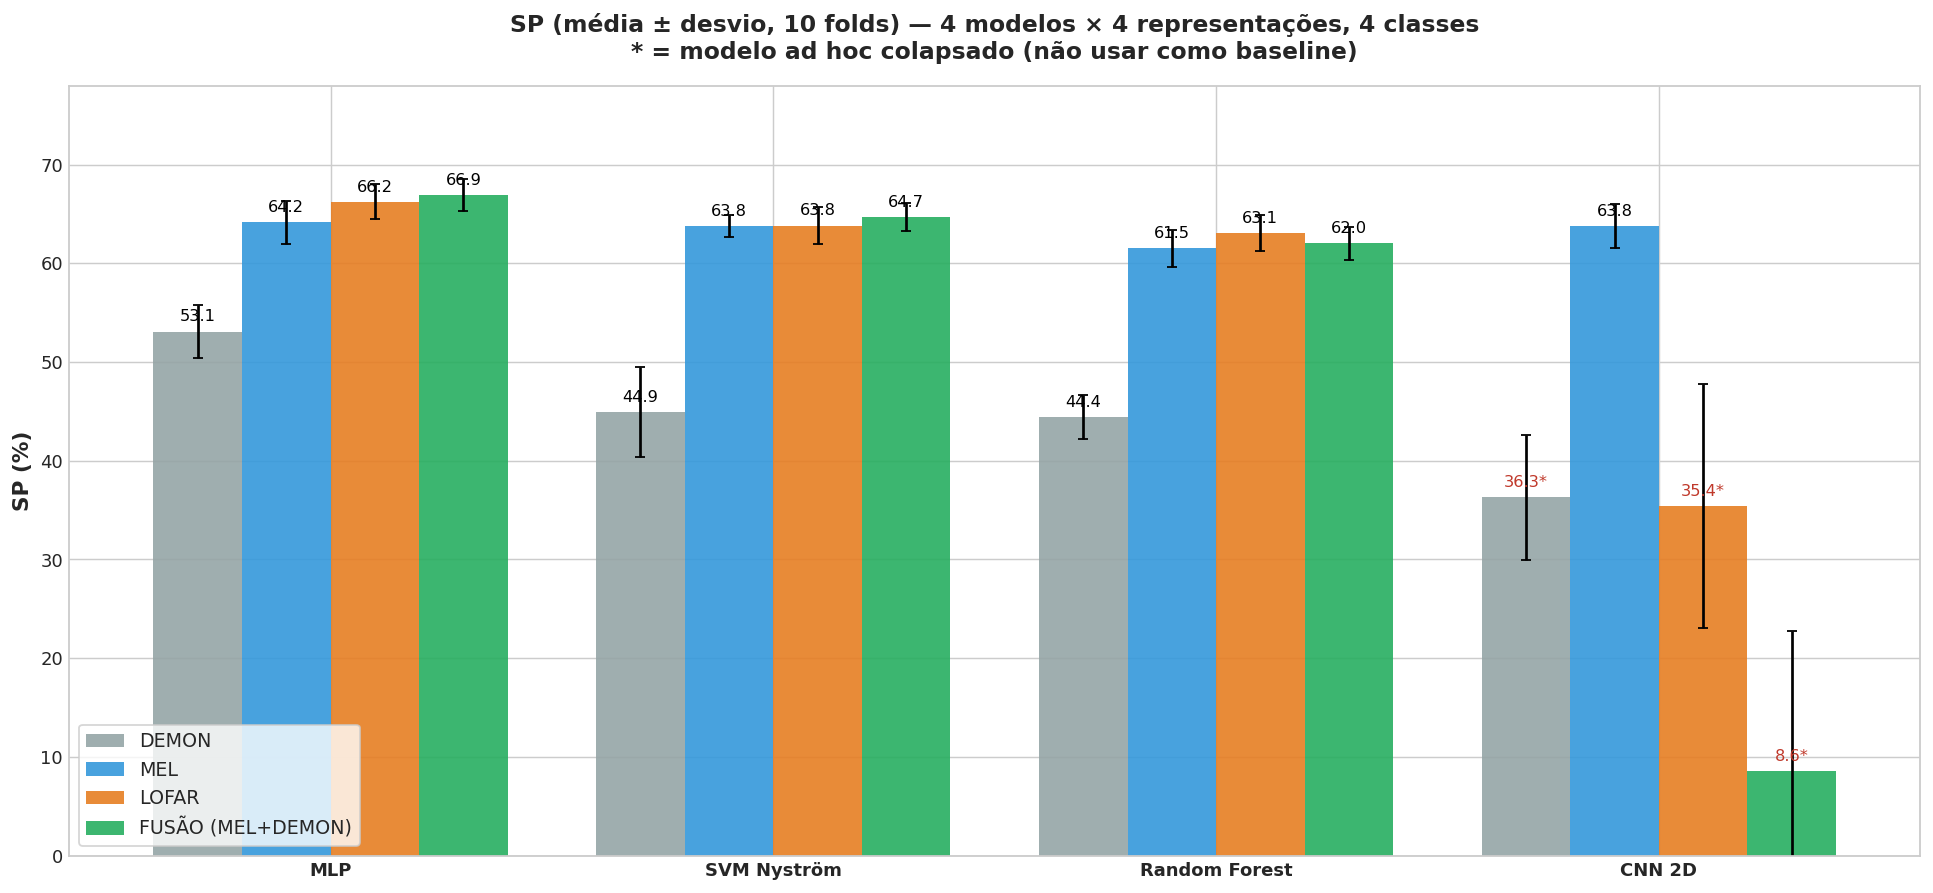

In [3]:
fig, ax = plt.subplots(figsize=(15, 7))
x = np.arange(len(MODELS)); width = 0.20
colors = {'DEMON': '#95a5a6', 'MEL': '#3498db', 'LOFAR': '#e67e22', 'FUSÃO (MEL+DEMON)': '#27ae60'}
for i, r in enumerate(REPS):
    vals = [S4[(m, r)]['SP'][0] for m in MODELS]
    errs = [S4[(m, r)]['SP'][1] for m in MODELS]
    rects = ax.bar(x + (i - 1.5) * width, vals, width, yerr=errs, capsize=3, label=r, color=colors[r], alpha=0.9)
    for m, rect in zip(MODELS, rects):
        h = rect.get_height()
        coll = 'COLAPSADA' in GRID[(m, r)][4]
        ax.annotate(f'{h:.1f}' + ('*' if coll else ''), xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 4),
                    textcoords='offset points', ha='center', va='bottom', fontsize=9, color='#c0392b' if coll else 'black')
ax.set_title('SP (média ± desvio, 10 folds) — 4 modelos × 4 representações, 4 classes\n* = modelo ad hoc colapsado (não usar como baseline)',
             fontweight='bold', fontsize=13, pad=15)
ax.set_ylabel('SP (%)', fontweight='bold'); ax.set_xticks(x); ax.set_xticklabels(MODELS, fontweight='bold')
ax.set_ylim(0, 78); ax.legend(loc='lower left', frameon=True, fontsize=10.5)
plt.tight_layout()
plt.show()

## 3. Gráfico 2: Recall da Classe Crítica `SMALL`

Nos modelos 4c (MLP, SVM, RF), o recall de SMALL vai de 38,15% a 47,81% com LOFAR e de 46,07% a 57,87% com MEL. Abaixo, o efeito da fusão com DEMON (à esquerda, modelos 4c; à direita, modelos retreinados sem BG, só onde existem):

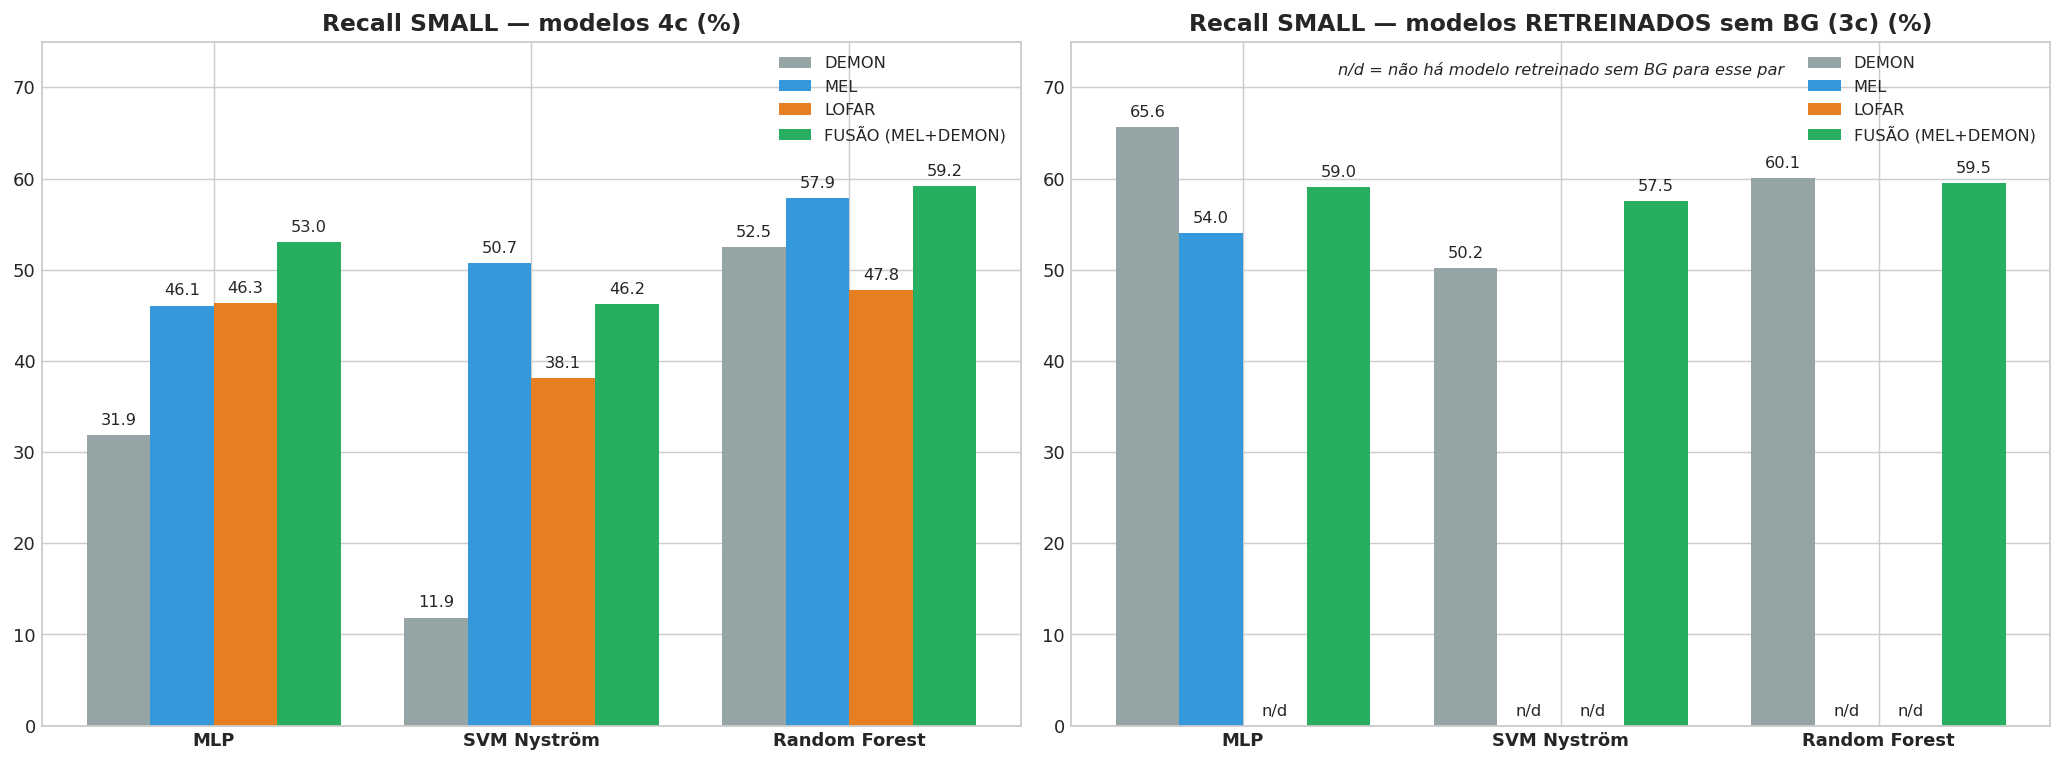

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
m3 = MODELS[:3]
x = np.arange(len(m3)); w = 0.2
for ax, S, title in [(ax1, S4, 'Recall SMALL — modelos 4c (%)'), (ax2, S3, 'Recall SMALL — modelos RETREINADOS sem BG (3c) (%)')]:
    for i, (r, c) in enumerate([('DEMON', '#95a5a6'), ('MEL', '#3498db'), ('LOFAR', '#e67e22'), ('FUSÃO (MEL+DEMON)', '#27ae60')]):
        vals = [S[(m, r)]['R_SMALL'][0] if (m, r) in S else np.nan for m in m3]
        rects = ax.bar(x + (i - 1.5) * w, vals, w, label=r, color=c)
        for rect, v in zip(rects, vals):
            ax.annotate('n/d' if np.isnan(v) else f'{v:.1f}', xy=(rect.get_x() + rect.get_width() / 2, 0 if np.isnan(v) else v),
                        xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9)
    ax.set_title(title, fontweight='bold'); ax.set_xticks(x); ax.set_xticklabels(m3, fontweight='bold')
    ax.set_ylim(0, 75); ax.legend(fontsize=9)
ax2.text(0.5, 0.97, 'n/d = não há modelo retreinado sem BG para esse par', transform=ax2.transAxes, ha='center', va='top', fontsize=9, style='italic')
plt.tight_layout()
plt.show()

## 4. Matrizes de Confusão da Fusão (MLP e SVM)

Matrizes por arquivo, acumuladas nas 10 dobras e normalizadas por linha:

In [5]:
CLS = ['SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND']


def confusion(exp):
    """Matriz por arquivo, ACUMULADA nas 10 dobras (instâncias arquivo x fold), normalizada por linha (%)."""
    df = pd.concat(R.file_predictions(exp).values(), ignore_index=True)
    rows = sorted(df.Target.unique()); cols = sorted(set(rows) | set(df.Prediction.unique()))
    cm = pd.crosstab(df.Target, df.Prediction).reindex(index=rows, columns=cols, fill_value=0)
    cmn = 100 * cm.div(cm.sum(axis=1), axis=0)
    cmn.index = [CLS[i] for i in rows]; cmn.columns = [CLS[i] for i in cols]
    return cmn


CM_KEYS = [('MLP', 'FUSÃO (MEL+DEMON)'), ('SVM Nyström', 'FUSÃO (MEL+DEMON)')]
CMS = {k: confusion(GRID[k][1]) for k in CM_KEYS}

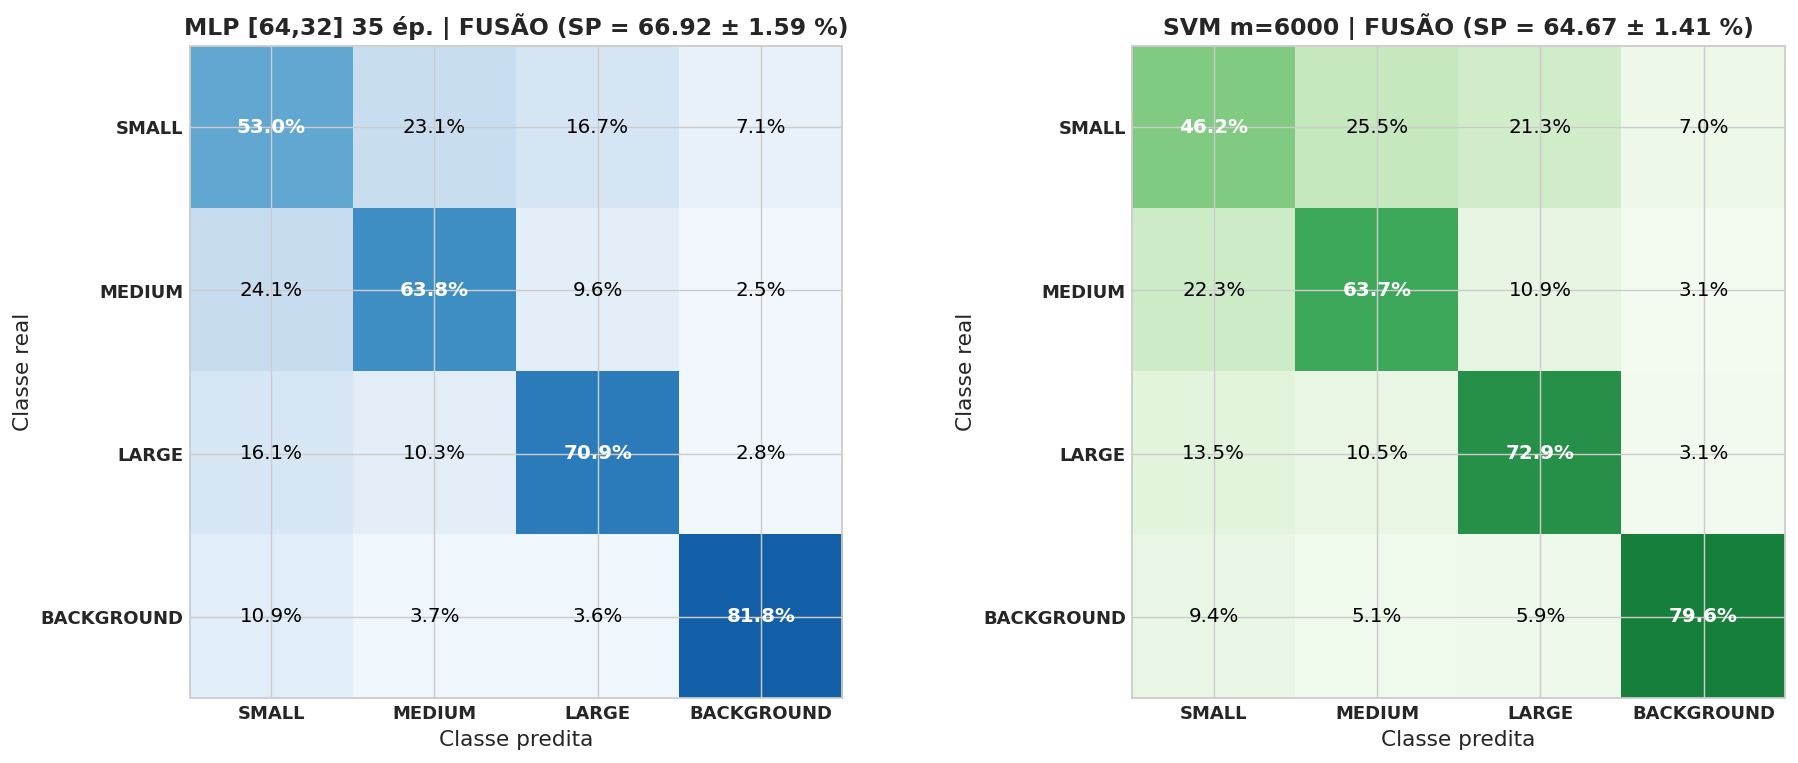

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, k, cmap in zip(axes, CM_KEYS, ['Blues', 'Greens']):
    cm = CMS[k]
    ax.imshow(cm.values, cmap=cmap, vmin=0, vmax=100)
    sp = S4[k]['SP']
    ax.set_title(f'{GRID[k][0]} (SP = {sp[0]:.2f} ± {sp[1]:.2f} %)', fontweight='bold')
    ax.set_xticks(range(4)); ax.set_yticks(range(4))
    ax.set_xticklabels(cm.columns, fontweight='bold'); ax.set_yticklabels(cm.index, fontweight='bold')
    ax.set_xlabel('Classe predita'); ax.set_ylabel('Classe real')
    for i in range(4):
        for j in range(4):
            v = cm.values[i, j]
            ax.text(j, i, f'{v:.1f}%', ha='center', va='center', color='white' if v > 45 else 'black',
                    fontweight='bold' if i == j else 'normal')
plt.tight_layout()
plt.show()

## 5. Testes Estatísticos (F-test 5x2cv)

FUSÃO contra cada entrada isolada da mesma família (SP e recall SMALL por fold). "Supera" só quando p < 0,05:

In [7]:
# F-test 5x2cv (Alpaydin), como no artigo: FUSÃO contra as entradas isoladas, por família (modelos 4c)
F = 'FUSÃO (MEL+DEMON)'
PAIRS = [(('MLP', F), ('MLP', 'LOFAR')), (('MLP', F), ('MLP', 'MEL')), (('MLP', F), ('MLP', 'DEMON')),
         (('SVM Nyström', F), ('SVM Nyström', 'LOFAR')), (('SVM Nyström', F), ('SVM Nyström', 'MEL')),
         (('Random Forest', F), ('Random Forest', 'LOFAR')), (('Random Forest', F), ('Random Forest', 'MEL'))]
rows = []
for a, b in PAIRS:
    for met in ('SP', 'R_SMALL'):
        f, p = R.f_test_5x2(GRID[a][1], GRID[b][1], metric=met)
        rows.append({'A': GRID[a][0], 'B': GRID[b][0], 'métrica': met, 'média A': round(S4[a][met][0], 2),
                     'média B': round(S4[b][met][0], 2), 'F': round(f, 2), 'p': round(p, 4), 'p < 0,05': p < 0.05,
                     '_a': a, '_b': b})
df_tests = pd.DataFrame(rows)
# Extra: MLP oficial MEL (0,512 s) contra MLP MEL 5,12 s, para medir o efeito da grade temporal
f, p = R.f_test_5x2('mlp', 'mlp_mel5s_h32-16_e35_4c')
grid_effect = {'F': f, 'p': p, 'oficial': R.summary('mlp')['SP'], 'mel5s': S4[('MLP', 'MEL')]['SP']}
display(df_tests.drop(columns=['_a', '_b']))
print(f"MLP MEL oficial (0,512 s) vs MLP MEL 5,12 s: F = {f:.2f}, p = {p:.4f}")

,A,B,métrica,média A,média B,F,p,"p < 0,05"
0,"MLP [64,32] 35 ép. | FUSÃO",MLP oficial | LOFAR,SP,66.92,66.24,0.75,0.6760,False
1,"MLP [64,32] 35 ép. | FUSÃO",MLP oficial | LOFAR,R_SMALL,53.03,46.35,1.91,0.2455,False
2,"MLP [64,32] 35 ép. | FUSÃO","MLP [32,16] 35 ép. | MEL 5,12 s",SP,66.92,64.16,1.45,0.3580,False
3,"MLP [64,32] 35 ép. | FUSÃO","MLP [32,16] 35 ép. | MEL 5,12 s",R_SMALL,53.03,46.07,0.92,0.5745,False
4,"MLP [64,32] 35 ép. | FUSÃO","MLP [32,16] 35 ép. | DEMON",SP,66.92,53.09,19.55,0.0021,True
5,"MLP [64,32] 35 ép. | FUSÃO","MLP [32,16] 35 ép. | DEMON",R_SMALL,53.03,31.85,3.52,0.0887,False
6,SVM m=6000 | FUSÃO,SVM m=6000 | LOFAR,SP,64.67,63.83,2.37,0.1770,False
7,SVM m=6000 | FUSÃO,SVM m=6000 | LOFAR,R_SMALL,46.24,38.15,1.48,0.3476,False
8,SVM m=6000 | FUSÃO,SVM m=4000 | MEL,SP,64.67,63.78,1.74,0.2809,False
9,SVM m=6000 | FUSÃO,SVM m=4000 | MEL,R_SMALL,46.24,50.73,1.28,0.4132,False


MLP MEL oficial (0,512 s) vs MLP MEL 5,12 s: F = 1.56, p = 0.3248


## 6. Conclusões

1. **A fusão MEL + DEMON é estatisticamente equivalente ao LOFAR em SP nas três famílias vetoriais — não o supera.**
   * **MLP:** FUSÃO 66,92 ± 1,59% × MLP LOFAR oficial 66,24 ± 1,78% (F = 0,75, p = 0,676: **equivalentes**); a MLP LOFAR da Tabela 7 do artigo tem 66,51 ± 1,39%. A comparação **favorece a FUSÃO**: a MLP da FUSÃO tem rede maior (`[64, 32]` contra `[32, 16]`) e outra grade temporal (5,12 s contra 0,512 s). Contra a MLP MEL 5,12 s `[32,16]` (mesma grade e script), F = 1,45, p = 0,358: **equivalentes**; contra a MLP DEMON, F = 19,55, p = 0,002: diferença **significativa**.
   * **SVM:** FUSÃO (m=6000) 64,67 ± 1,41% × SVM LOFAR m=6000 63,83 ± 1,91% (F = 2,37, p = 0,177: **equivalentes**) e × SVM MEL m=4000 63,78 ± 1,14% (F = 1,74, p = 0,281: **equivalentes**).
   * **Random Forest:** FUSÃO 62,04 ± 1,66% × RF LOFAR 5,12 s local 63,07 ± 1,81% (F = 1,34, p = 0,393: **equivalentes**) e × RF MEL 5,12 s 61,50 ± 1,89% (F = 0,82, p = 0,633: **equivalentes**). O RF LOFAR local tem SP média **maior** que a RF FUSÃO. (O RF LOFAR da Tabela 7 do artigo, 56,92 ± 1,69%, não é comparável: grade e hiperparâmetros diferentes.)
   * **Recall SMALL:** a FUSÃO eleva o recall de SMALL em relação ao LOFAR na RF (59,16% × 47,81%; F = 7,92, p = 0,017: diferença **significativa**); na MLP (53,03% × 46,35%; F = 1,91, p = 0,245: **equivalentes**) e no SVM (46,24% × 38,15%; F = 1,48, p = 0,348: **equivalentes**).
   * A FUSÃO tem metade da dimensão do LOFAR (509 × 1024) com SP estatisticamente equivalente; isto é o que os dados sustentam.

2. **A CNN 2D ad hoc colapsa na fusão:** SP 8,60 ± 14,13% (folds: 0,0, 0,0, 0,0, 0,0, 0,0, 42,1, 0,0, 0,0, 21,7, 22,2). A CNN ad hoc também colapsa em DEMON (36,28 ± 6,38%) e em LOFAR 5,12 s (35,40 ± 12,38%, contra 66,05 ± 1,90% da CNN LOFAR da Tabela 7 do artigo), então o colapso não pode ser atribuído à fusão. *Hipótese (não testada):* a fronteira artificial entre os 256 canais MEL e os 253 canais DEMON não tem continuidade física para convoluções 2D.

3. **MLP FUSÃO:** tem a maior SP média local (66,92 ± 1,59%, recall SMALL 53,03%, 23,1% dos SMALL indo para MEDIUM na matriz acumulada), mas **sem diferença estatística** para a MLP LOFAR oficial. O efeito da grade temporal também precisa ser considerado: MLP MEL oficial (0,512 s) 64,74 ± 2,05% × MLP MEL 5,12 s 64,16 ± 2,19% (F = 1,56, p = 0,325).